# Previsão de Churn com Regressão Logística

Base: [Telco Customer Churn — Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn).

O objetivo é classificar se um cliente pode cancelar o serviço (`Churn`).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

In [ ]:
# Carregar os dados
arquivo = files.upload()
nome_arquivo = next(nome for nome in arquivo if nome.lower().endswith('.csv'))
dados = pd.read_csv(nome_arquivo)

dados.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Preparar os dados
dados.columns = dados.columns.str.strip()
for coluna in dados.select_dtypes(include='object').columns:
    dados[coluna] = dados[coluna].str.strip()

dados['TotalCharges'] = pd.to_numeric(dados['TotalCharges'], errors='coerce')
dados = dados.dropna(subset=['Churn'])
dados['TotalCharges'] = dados['TotalCharges'].fillna(dados['TotalCharges'].median())
dados = dados.drop(columns=['customerID'], errors='ignore')

y = dados['Churn'].map({'No': 0, 'Yes': 1})
x = pd.get_dummies(dados.drop(columns='Churn'), drop_first=True, dtype=int)

print('Dimensões:', dados.shape)
print('Clientes que cancelaram:', int(y.sum()))

Dimensões: (7043, 20)
Clientes que cancelaram: 1869


In [ ]:
# Separar treino e teste
x_treino, x_teste, y_treino, y_teste = train_test_split(
    x, y, test_size=0.20, random_state=42, stratify=y
)

# Padronizar os dados usando apenas o conjunto de treino
escala = StandardScaler()
x_treino = escala.fit_transform(x_treino)
x_teste = escala.transform(x_teste)

In [ ]:
# Treinar o modelo
modelo = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
modelo.fit(x_treino, y_treino)

y_pred = modelo.predict(x_teste)
y_prob = modelo.predict_proba(x_teste)[:, 1]
print('Treinamento concluído.')

Treinamento concluído.


In [ ]:
# Avaliar o modelo
print(f'Acurácia: {accuracy_score(y_teste, y_pred):.3f}')
print(f'Precisão: {precision_score(y_teste, y_pred, zero_division=0):.3f}')
print(f'Recall: {recall_score(y_teste, y_pred, zero_division=0):.3f}')
print(f'F1-score: {f1_score(y_teste, y_pred, zero_division=0):.3f}')
print(f'ROC-AUC: {roc_auc_score(y_teste, y_prob):.3f}')

# Recall e ROC-AUC ajudam a analisar a identificação de clientes com risco de cancelamento.

Acurácia: 0.739
Precisão: 0.505
Recall: 0.781
F1-score: 0.613
ROC-AUC: 0.841


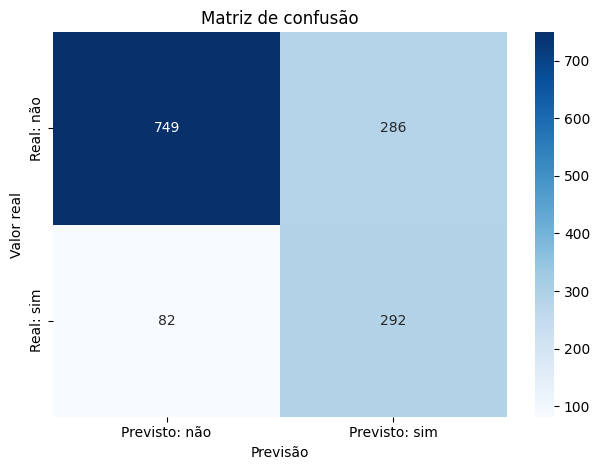

In [ ]:
# Matriz de confusão
matriz = confusion_matrix(y_teste, y_pred, labels=[0, 1])
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Previsto: não', 'Previsto: sim'],
            yticklabels=['Real: não', 'Real: sim'])
plt.xlabel('Previsão')
plt.ylabel('Valor real')
plt.title('Matriz de confusão')
plt.tight_layout()
plt.show()